# Modelo de **Hodgkin & Huxley**

Referencias:

1. https://en.wikipedia.org/wiki/Hodgkin%E2%80%93Huxley_model
2. Eugene M. Izhikevich, Dynamical Systems in Neuroscience: The Geometry of Excitability and Bursting, Computational Neuroscience, The MIT Press (2006)
3. https://colab.research.google.com/github/kmkarakaya/ML_tutorials/blob/master/How_to_upload_an_image_to_Colab_.ipynb#scrollTo=KKTpNAGCWLeB

## **Ejercicio 1)** Importando librerías

**a)** Importe las librerías `numpy` para operar con arrays, `scipy` para utilizar rutinas de algebra lineal y `matplotlib.pyplot` para graficar.

**b)** Suba el archivo "libreria" `ode.py` que fabricó en el práctico 4), e impórtelo.

In [1]:
# 1.a)
import numpy as np
import scipy as sp
import scipy.linalg as linalg
import matplotlib.pyplot as plt

## **Ejercicio 2)** Modelo de Hodgkin y Huxley

## Teoría

### Las neuronas son capacitores

Según el modelo de Hodgkin y Huxley, a primera vista las neuronas funcionan como capacitores evidenciando una diferencia de potencial eléctrico entre el exterior y el interior debido a las diferentes concentraciones de cargas iónicas que pueden existir entre estas dos regiones.
En el esquema, se utilizan agujas muy finas para inyectar una corriente iónica $i$ al interior de una neurona sumergida en una solución salina conductora.

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/esquema1.png?raw=true:, width=100" alt="My Image" width=300>

Recordemos que un capacitor sujeto a una diferencia de potencial $v:=v_A-v_B$ adquiere una carga $q=cv$.
La carga crece según $\dot{q}=i$, donde $i$ denota la corriente de carga eléctrica que va desde el exterior hacia el interior.

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/circuito1.png?raw=true:, width=100" alt="My Image" width=500>

### Las neuronas son capacitores con fugas

Si miramos un poco más en detalle, veremos que la membrana de las neuronas tienen canales por donde pueden circular iones.
Podemos pensar a los canales como agujeritos en la membrana por donde la carga se fuga, que podemos modelar como a una resistencia conectada en paralelo al capacitor.

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/circuito2.png?raw=true:, width=100" alt="My Image" width=500>

La corriente $i_g=g(v_A-v_B)=gv$, donde $i_g$ denota una corriente que va desde el interior hacia el exterior.

### Las neuronas tienen generadores de tensión

Los canales pueden ser selectivos.
Por ejemplo, algunos canales sólo dejan pasar los iones $\mathrm{K}^+$.
Por ende, si inyectamos al interior de la neurona una mezcla de iones $\mathrm{K}^+$ y $\mathrm{Cl}^-$, de manera que la carga total se encuentre equilibrada, los iones $\mathrm{K}^+$ comenzarán a difundir desde el interior hacia el exterior a travéz de los canales selectivos, mientras que los de $\mathrm{Cl}^-$ se quedarán en el interior, provocando un excedente de cargas negativas en el interior que crecen en el tiempo hasta que la diferencia de potencial emergente frena la corriente de iónes $\mathrm{K}^+$.

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/baterias.png?raw=true:, width=100" alt="My Image" width=500>

A este fenómeno se lo denomina potencial de Nernst o de reversión y se lo incorpora al circuito que modela la neurona como una batería conectada en serie a la resistencia asociada a cada canal

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/circuito3.png?raw=true:, width=100" alt="My Image" width=500>

Ahora, la corriente es $i_g=g(v_A-v_C)=g(v_A-(v_B+e_g))=g(v_A-v_B-e_g)=g(v-e_g)=:g(v-v_g)$, donde en la última iguadad reconocemos la definición del potencial de Nernst $v_g$.

Si la batería se encuentra en sentido inverso

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/circuito4.png?raw=true:, width=100" alt="My Image" width=500>

entonces $i_g=g(v_A-v_C)=g(v_A-(v_B-e_g))=g(v_A-v_B+e_g)=g(v+e_g)=:g(v-v_g)$, por lo que el potencial de Nernst resulta negativo, $v_g=-e_g$.

### Algunos canales forman reóstatos (resistencias de conductancia variable)

Algunos canales tienen varias compuertas que se abren o cierran, permitiendo o impidiendo el paso de iones. Un mismo canal puede tener varias compuertas, y para que el canal sea conductor deben encontrarse abiertas las compuertas correspondientes.

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/compuertas.png?raw=true:, width=100" alt="My Image" width=500>

La conductividad asociada a estos canales, depende de la fracción de compuertas abiertas en cada tipo de canal.
Según el modelo, la conductancia total asociada a los canales de $\mathrm{Na}$ se aproxima por

$$g_{\mathrm{Na}} = \bar{g}_{\mathrm{Na}}p_{\mathrm{Na}}$$

donde $\bar{g}_{\mathrm{Na}}$ es la conductancia de $\mathrm{Na}$ máxima posible y

$$p_{\mathrm{Na}} = m^3h$$

es la fracción de canales de $\mathrm{Na}$ que se encuentran en estado conductor.
Aquí $m$ y $h$ son las fracciones de compuertas de activación e inactivación, respectivamente, que se encuentran abiertas.
Los canales de $\mathrm{Na}$ poseen 3 compuertas de activación y 1 de inactivación, por lo que, asumiendo que se abren de manera independiente, $m$ tiene un exponente 3 y $h$ un exponente 1.

De manera similar, la conductancia asociada a los canales de $\mathrm{K}$ se aproxima por

$$g_{\mathrm{K}} = \bar{g}_{\mathrm{K}}p_{\mathrm{K}}$$

donde $\bar{g}_{\mathrm{K}}$ es la conductancia de $\mathrm{K}$ máxima posible,

$$p_{\mathrm{K}} = n^4$$

es la fracción de canales de $\mathrm{K}$ abiertos y $n$ es la fracción de compuertas abiertas en este tipo de canales.
Cada canal de $\mathrm{K}$ posee 4 compuertas de tipo $n$, de ahí el exponente 4.

Estas aproximaciones asumen que las compuertas abren o cierran de manera independiente, dependiendo de la diferencia de potencial de membrana existente $v$.
Más precisamente, las fracciones de compuertas abiertas de cada tipo satisfacen

\begin{eqnarray}
\dot{n}(t)&=&\alpha_n(v(t))(1-n(t))-\beta_n(v(t)) n(t)\\
\dot{m}(t)&=&\alpha_m(v(t))(1-m(t))-\beta_m(v(t)) m(t)\\
\dot{h}(t)&=&\alpha_h(v(t))(1-h(t))-\beta_h(v(t)) h(t)
\end{eqnarray}

donde

\begin{eqnarray}
\alpha_h(v)&=&\frac{0.07}{ms}\,\exp\bigg(-\frac{v}{20\,mV}\bigg)\\
\alpha_m(v)&=&\frac{0.1}{ms\,mV}\frac{25\,mV-v}{\exp\big(\frac{25\,mV-v}{10\,mV}\big)-1}\\
\alpha_n(v)&=&\frac{0.01}{ms\,mV}\frac{10\,mV-v}{\exp\big(\frac{10\,mV-v}{10\,mV}\big)-1}\\
\end{eqnarray}

representan las tasas a las cuales las compuertas cerradas de cada tipo abren y

\begin{eqnarray}
\beta_h(v)&=&\frac{1}{ms}\frac{1}{\exp\big(\frac{30\,mV-v}{10\,mV}\big)+1}\\
\beta_m(v)&=&\frac{4}{ms}\exp\bigg(-\frac{v}{18\,mV}\bigg)\\
\beta_n(v)&=&\frac{0.125}{ms}\exp\bigg(-\frac{v}{80\,mV}\bigg)
\end{eqnarray}

representan las tasas a las cuales las compuertas abiertas de cada tipo cierran, respectivamente.

En resumen, al modelo de neurona de Hodgkin y Huxley se lo puede representar por el circuito

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/circuito5.png?raw=true:, width=100" alt="My Image" width=500>

en donde reconocemos la existencia de 3 canales iónicos: uno de pérdida (leak) de conductancia constante $g_l$, potencial de Nernst $v_l=e_l$ y por el que fluye una corriente $i_l$, uno de $\mathrm{Na}$ de conductancia variable $g_{\mathrm{Na}}$, potencial de Nernst $v_{\mathrm{Na}}=e_{\mathrm{Na}}$ y por el que fluye una corriente $i_{\mathrm{Na}}$, y uno de $\mathrm{K}$ de conductancia $g_{\mathrm{K}}$, potencial de Nernst $v_{\mathrm{K}}=-e_{\mathrm{K}}$ y por el que fluye una corriente $i_{\mathrm{K}}$.

Aplicando la ley de Kirchoff para corrientes, vemos que

$$i=i_{\mathrm{Na}}+i_{\mathrm{K}}+i_l+i_c$$

Es decir, la corriente $i$ inyectada al interior de la neurona se divide en dos partes.
Por un lado, en la corriente $i_m=i_{\mathrm{Na}}+i_{\mathrm{K}}+i_l$ que fluye a travéz de los canales en la membrana,
y por otro lado, en la corriente $i_c$ que carga el capacitor.

Remplazando, obtenemos una ODE para el potencial de membrana

\begin{eqnarray}
i_c&=&i-i_{\mathrm{Na}}+i_{\mathrm{K}}+i_l\\
c\dot{v}&=&i-g_{\mathrm{Na}}(v-v_{\mathrm{Na}})-g_{\mathrm{K}}(v-v_{\mathrm{K}})-g_{l}(v-v_{l})\\
\dot{v}&=&c^{-1}(i-\bar{g}_{\mathrm{Na}}m^3h(v-v_{\mathrm{Na}})-\bar{g}_{\mathrm{K}}n^4(v-v_{\mathrm{K}})-g_{l}(v-v_{l}))
\end{eqnarray}

La última línea de la anterior ecuación, junto con las ODEs anteriormente mencionadas para $n$, $m$ y $h$, determinan el sistema de ODEs del modelo de Hodgkin y Huxley.

### Comportamiento cualitativo

Durante el proceso de disparo, diferentes compuertas se abren y cierran a diferentes tiempos.
El siguiente esquema resume el proceso en 4 etapas

<img src="https://github.com/jipphysics/redes-neuronales-2022/blob/master/practicos/assets/channels.png?raw=true:, width=100" alt="My Image" width=300>

Estimaciones de los tiempos carácterísticos (de apertura/cierre) y los valores de equilibrio de las fracciones de compuertas abiertas de cada tipo que observan en las diferentes etapas, se pueden obtener de reescribir las ODEs para $n$, $m$ y $h$ de la forma

\begin{eqnarray}
\dot{n}(t)&=&\tau_n^{-1}(v(t))(n_{\infty}(v(t))-n(t))\\
\dot{m}(t)&=&\tau_m^{-1}(v(t))(m_{\infty}(v(t))-m(t))\\
\dot{h}(t)&=&\tau_h^{-1}(v(t))(h_{\infty}(v(t))-h(t))
\end{eqnarray}

donde

\begin{eqnarray}
\tau_n(v)&=&(\alpha_n(v)+\beta_n(v))^{-1}\\
\tau_m(v)&=&(\alpha_m(v)+\beta_m(v))^{-1}\\
\tau_h(v)&=&(\alpha_h(v)+\beta_h(v))^{-1}
\end{eqnarray}

y

\begin{eqnarray}
n_{\infty}(v)&=&\tau_n(v)\alpha_n(v)\\
m_{\infty}(v)&=&\tau_m(v)\alpha_m(v)\\
h_{\infty}(v)&=&\tau_h(v)\alpha_h(v)
\end{eqnarray}

Finalmente, listamos los valores de los parámetros del modelo (ver libro de Izhikevich)

* $c=1\,\mu F/cm^2$ : capacitancia de membrana
* $\bar{g}_{\mathrm{Na}}=120\,mS/cm^2$ : conductancia máxima de $\mathrm{Na}$
* $\bar{g}_{\mathrm{K}}=36\,mS/cm^2$ : conductancia máxima de $\mathrm{K}$
* $g_l=0.3\,mS/cm^2$ : conductancia máxima de perdida
* $v_{\mathrm{Na}}=120\,mV$ : potencial de reversión de la corriente de $\mathrm{Na}$
* $v_{\mathrm{K}}=-12\,mV$ : potencial de reversión de la corriente de $\mathrm{K}$
* $v_l=10.6\,mV$ : potencial de reversión de la corriente de perdida
* $i(t)\sim 10\,\mu A/cm^2$ : corriente de entrada al tiempo $t$
* $t \sim 5\,ms$ : tiempo

Aclaración, los valores de los potenciales de Nernst se toman en referencia al potencial de equilibrio definido en $v\approx 0\, mV$.

## Ejercicio 2) implementación

**1)** Usando la sección de teoría y las referencias, implemente el modelo de Hodgkin y Huxley el integrador numérico de ODEs tipo Runge-Kutta de orden 4 del práctico 4.

**2)** Grafique los valores de equilibrio de las distintas fracciones $n_{\infty}$, $m_{\infty}$ y $h_{\infty}$ de compuertas abiertas, en función de la diferencia de potencial de membrana $v$.

**3)** Grafique los tiempos característicos $\tau_m$, $\tau_n$ y $\tau_h$ de apertura y cierre, asociados a los distintos tipos de compuertas, en función de la diferencia de potencial de membrana $v$.

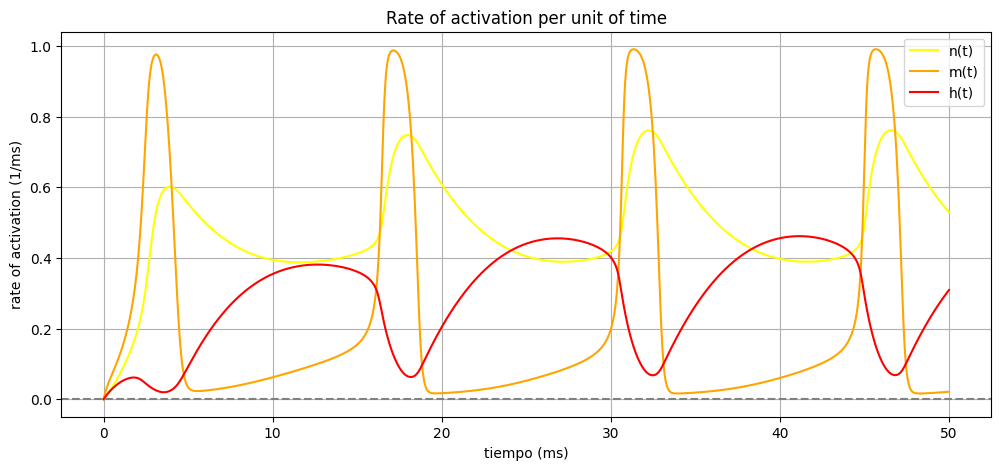

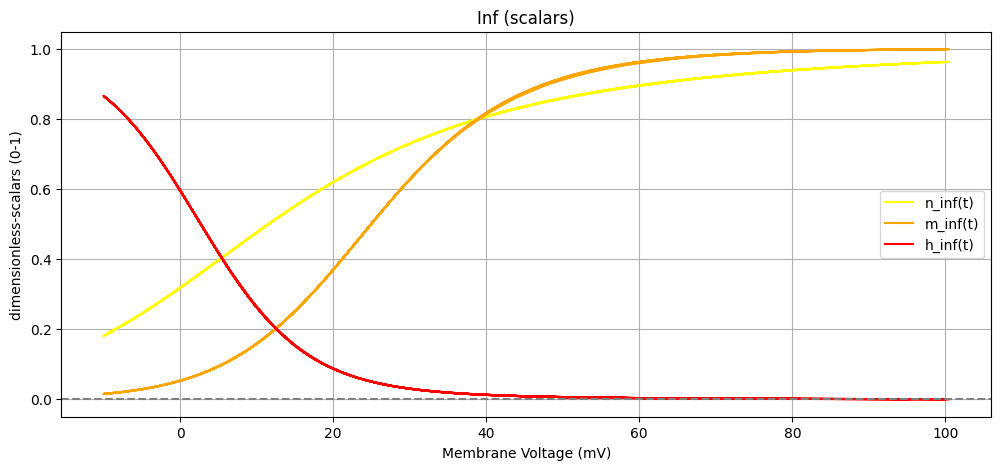

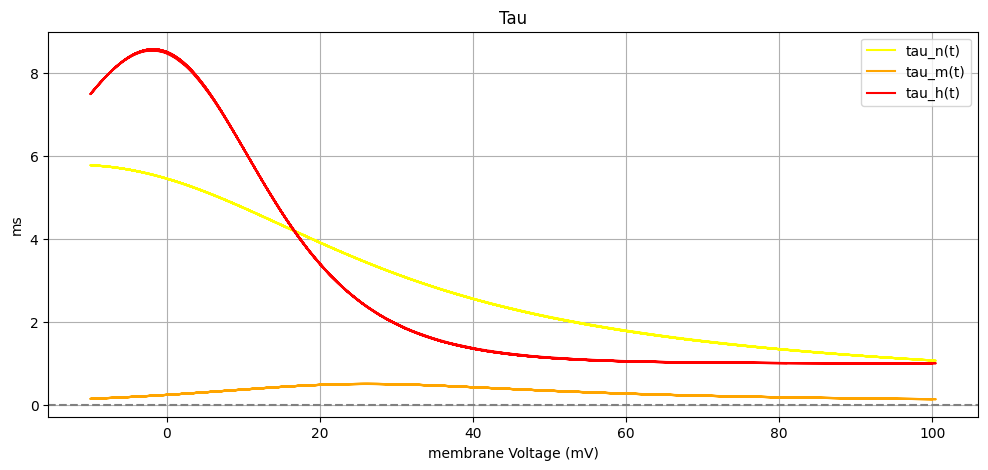

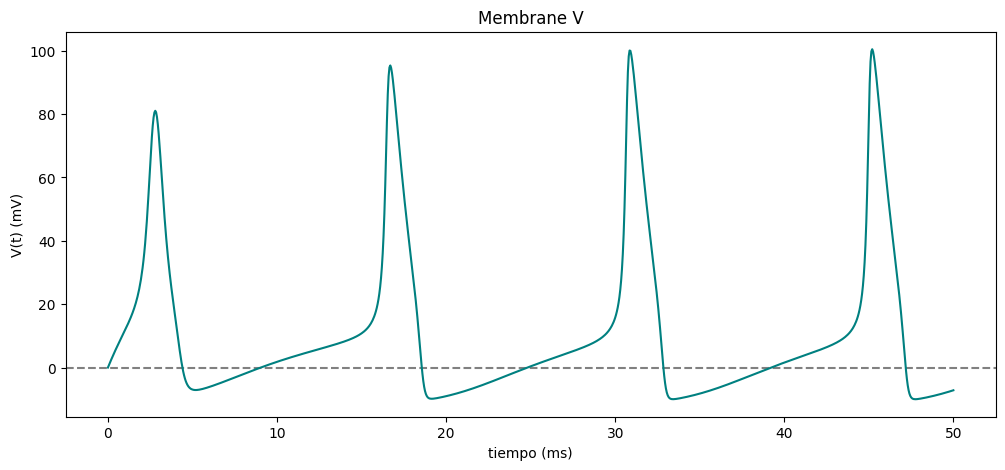

In [21]:
# 1.a)
import numpy as np
import scipy as sp
import scipy.linalg as linalg
import matplotlib.pyplot as plt


# 1.b)
# https://stackoverflow.com/questions/48905127/importing-py-files-in-google-colab
#import ode

def euler(f, x, t, h, p):
    return x + h * f(x, t, p)


def rk4(f, x, t, h, p):
    k1 = f(x, t, p)
    k2 = f(x + 0.5 * h * k1, t + 0.5 * h, p)
    k3 = f(x + 0.5 * h * k2, t + 0.5 * h, p)
    k4 = f(x + h * k3, t + h, p)
    return x + h * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0


def integrador_ode(m, f, xa, a, b, k, p, c=lambda x, t, p: x):
    assert k > 0
    n = len(xa)
    h = (b - a) / k
    w = np.zeros((n, k + 1))  # Produce un array con forma y tipo especificada con los parametros,
    # lleno de ceros. la forma puede ser espcificada con un entero o tupla (n,k+1)
    t = np.zeros(k + 1)
    w[:, 0] = xa  # actualiza la posicion inicial (columna de indice 0) de las variables con los valores
    # de las condiciones iniciales
    t[0] = a  # actualiza la posicion cero con el valor del tiempo inicial

    for j in range(k):  #Aca se produce la iteración en j

        t[j + 1] = t[j] + h  # iteracion tiempo
        w[:, j + 1] = m(f, w[:, j], t[j], h, p)  # iteracion de w
        w[:, j + 1] = c(w[:, j + 1], t[j + 1], p)  # condicion sobre w

    return t, w


def integrador_ode_2(m, f, xa, a, b, k, p, Ifunc, c=lambda x, t, p: x):
    assert k > 0
    n = len(xa)
    h = (b - a) / k
    w = np.zeros((n, k + 1))  # Produce un array con forma y tipo especificada con los parametros,
    t = np.zeros(k + 1)
    I_C = np.zeros(k + 1)
    w[:, 0] = xa  # actualiza la posicion inicial (columna de indice 0) de las variables con los valores
    t[0] = a  # actualiza la posicion cero con el valor del tiempo inicial
    I_C[0] = t[0]
    w_pp = []

    # extra --> (triggered??, replacer, triggerer)

    for j in range(k):  #Aca se produce la iteración en j

        t[j + 1] = t[j] + h  # iteracion tiempo
        w[:, j + 1] = m(f, w[:, j], t[j], h, p)  # iteracion de w
        w[:, j + 1], extra = c(w[:, j + 1], t[j + 1], p)  # condicion sobre w
        I_C[j + 1] = Ifunc(t[j + 1])

        if extra[0]:  # Triggered???
            w_pp.append((t[j + 1], extra[2]))  # triggerer registry
            w[:, j] = extra[1]  #get replaced!!! by upper threshold

        # Si el anterior dio 21mV el siguente me da 41mV >= umbral ==> j+1 = -65mV y pongo a j en 30mV
        # Si comentamos el remplazador y uso paso de integracion muy chico h=0.001, graficamente se ve igual.

    return t, w, I_C, w_pp


# 2.1) https://github.com/openworm/hodgkin_huxley_tutorial/blob/master/notebooks/Python_HH_version/Python_Notebook_HH.ipynb

# LIBRO PDF IZHI PAG= 61

#better implementation --> https://github.com/swharden/pyHH/blob/master/src/pyhh/models.py

c = 1  # 1uF/cm^2
gNa = 120  # mS/cm^2
gK = 36  # mS/cm^2
gL = 0.3  # mS/cm^2
vNa = 120  # mV
vK = -12  # mV
vL = 10.6  # mV
i0 = 10  # uA/cm^2
t0 = 5  # ms


def alpha_n(v):
    return 0.01 * ((10 - v) / (np.exp((10 - v) / 10) - 1))


def alpha_m(v):
    return 0.1 * ((25 - v) / (np.exp((25 - v) / 10) - 1))


def alpha_h(v):
    return 0.07 * np.exp(-v / 20)


def beta_n(v):
    return 0.125 * np.exp(-v / 80)


def beta_m(v):
    return 4 * np.exp(-v / 18)


def beta_h(v):
    return 1 / (np.exp((30 - v) / 10) + 1)


def tau_n(v):
    return 1 / (alpha_n(v) + beta_n(v))


def tau_m(v):
    return 1 / (alpha_m(v) + beta_m(v))


def tau_h(v):
    return 1 / (alpha_h(v) + beta_h(v))


def n_inf(v):
    return tau_n(v) * alpha_n(v)


def m_inf(v):
    return tau_m(v) * alpha_m(v)


def h_inf(v):
    return tau_h(v) * alpha_h(v)


def dn_dt(v, n):  # activación de los canales de potasio
    return (n_inf(v) - n) / tau_n(v)


def dm_dt(v, m):  # activación de los canales de sodio
    return (m_inf(v) - m) / tau_m(v)


def dh_dt(v, h):  # inactivación de los canales de sodio
    return (h_inf(v) - h) / tau_h(v)


def I(t):
    return i0


def dv_dt(v, m, n, h, t):
    return (1 / c) * (I(t) - gNa * pow(m, 3) * h * (v - vNa) - gK * pow(n, 4) * (v - vK) - gL * (v - vL))


def dALLdt(X, t, p):
    V, n, m, h = X
    dVdt = dv_dt(V, m, n, h, t)
    dndt = dn_dt(V, n)
    dmdt = dm_dt(V, m)
    dhdt = dh_dt(V, h)
    return np.array([dVdt, dndt, dmdt, dhdt])


V0, n0, m0, h0 = 0, 0, 0, 0
h = 0.05
ti = 0.0

tf = 50.0

k = int((tf - ti) / h)
t, w = integrador_ode(rk4, dALLdt, np.array([V0, m0, n0, h0]), ti, tf, k, [])

# These describe how quickly the gating variables approach their steady-state values.
# Output: Time constants in ms.
plt.figure(figsize=(12, 5))
plt.title(f"Tau")
plt.xlabel('membrane Voltage (mV)')
plt.ylabel('ms')
plt.plot(w[0, :], np.array([tau_n(x) for x in w[0, :]]), label="tau_n(t)", linestyle='-', c='yellow')
plt.plot(w[0, :], np.array([tau_m(x) for x in w[0, :]]), label="tau_m(t)", linestyle='-', c='orange')
plt.plot(w[0, :], np.array([tau_h(x) for x in w[0, :]]), label="tau_h(t)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')

plt.legend()
plt.grid()
plt.style.use('default')
plt.show()

# If we have 0.1/ms for n, the n proportion of activated channels is increasing by 0.1 per unit of time.
# In a pop. of 1000, n = 0.2 then 200 activated channels
plt.figure(figsize=(12, 5))
plt.xlabel('Membrane Voltage (mV)')
plt.title(f"Inf (scalars)")
plt.ylabel('dimensionless-scalars (0-1)')
plt.plot(w[0, :], np.array([n_inf(x) for x in w[0, :]]), label="n_inf(t)", linestyle='-', c='yellow')
plt.plot(w[0, :], np.array([m_inf(x) for x in w[0, :]]), label="m_inf(t)", linestyle='-', c='orange')
plt.plot(w[0, :], np.array([h_inf(x) for x in w[0, :]]), label="h_inf(t)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')

plt.legend()
plt.grid()
plt.style.use('default')
plt.show()



## Ejercicio 3) valores de equilibrio

**1)** Integre el sistema de ODEs del modelo de Hodgkin y Huxley sujeto a una corriente total $i(t)=0$ para todo $t$. Use la condición inicial $v_0=0mV$, $n_0=m_0=h_0=0$ y $t_0=0ms$. Integre hasta el tiempo final $t_f=500ms$ usando un paso temporal $dt=0.01ms$.

**2)** Grafique el potencial de membrana en función del tiempo, i.e. grafique $v(t)$ vs $t$ en el rango calculado.

**3)** Grafique las diferentes corrientes de iones cruzando la membrana en función del tiempo, i.e. grafique  la corriente de iones de sodio $i_{Na}(t)$, la corriente de iones de potasio $i_K(t)$ y la corriente de pérdida $i_l(t)$ vs $t$ en el rango calculado.

**4)** Grafique las fracción de compuertas abiertas de cada tipo en función del tiempo, i.e. grafique $n(t)$, $m(t)$ y $h(t)$ vs $t$ en el rango calculado.

**5)** Almacene los valores de equilibrio a corriente nula de las variables dinámicas usando los valores de las mismas obtenidos a tiempos largos. Es decir, almacene los valores $v^* \approx v(t_f)$, $n^* \approx n(t_f)$, $m^* \approx m(t_f)$ y $h^* \approx h(t_f)$, para ser utilizado como condiciones iniciales en futuras integraciones de las ODEs del modelo de Hodgkin y Huxley.

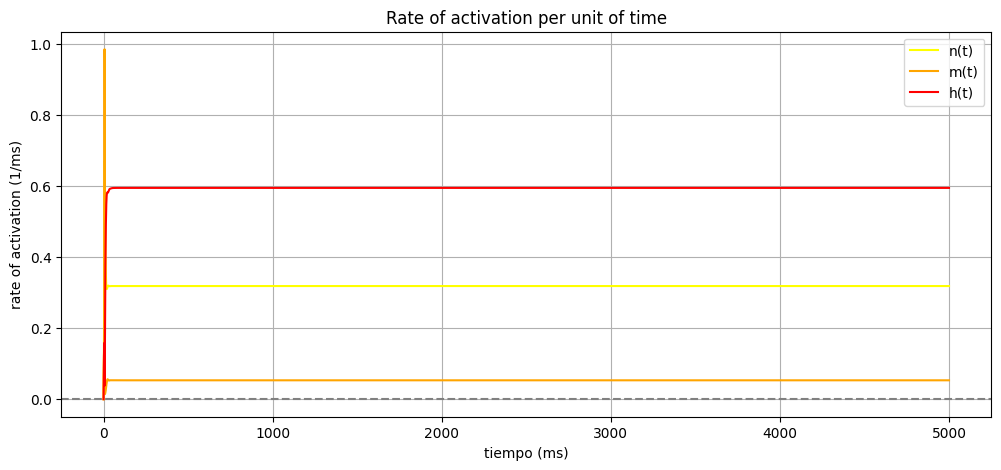

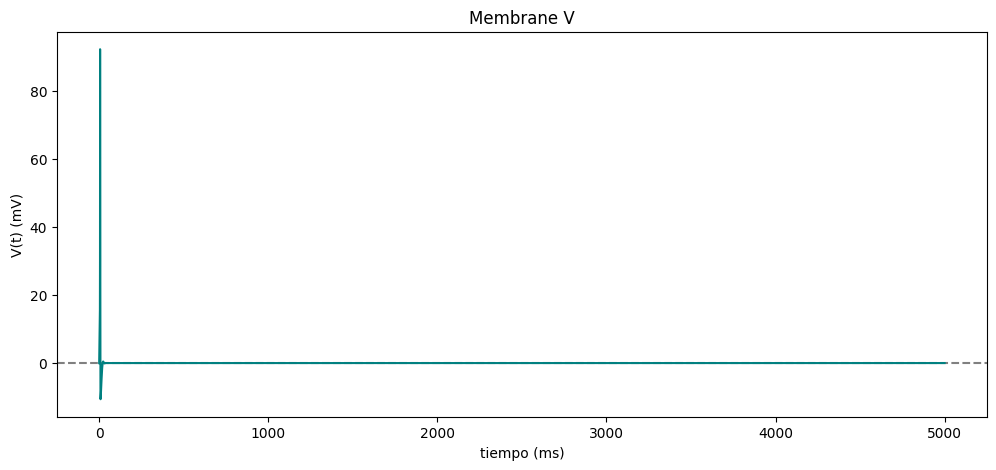

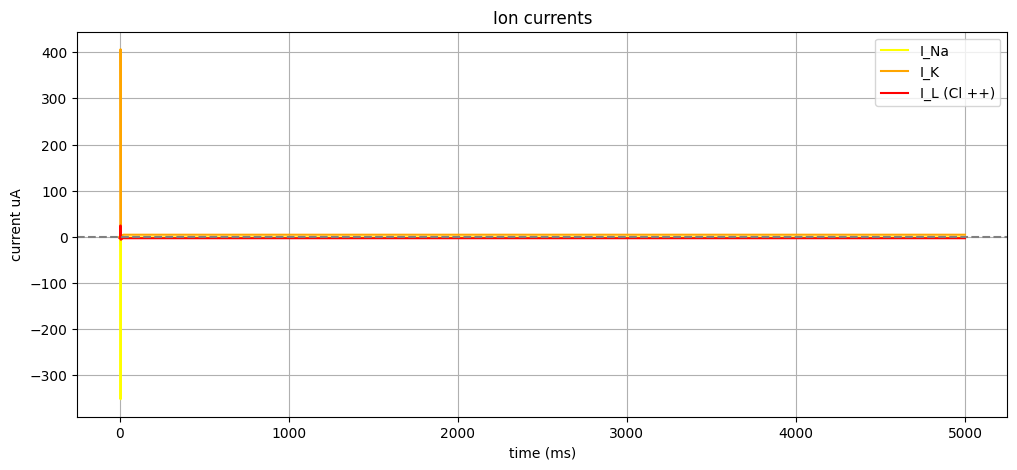

0.0462148579390762
0.3183853623363439
0.05322162937343748
0.594503593016988


In [28]:
# 3.1)
c = 1  # 1uF/cm^2
gNa = 120  # mS/cm^2
gK = 36  # mS/cm^2
gL = 0.3  # mS/cm^2
vNa = 120  # mV
vK = -12  # mV
vL = 10.6  # mV
i0 = 0  # uA/cm^2
t0 = 0  # ms

V0, n0, m0, h0 = 0, 0, 0, 0
h = 0.01
ti = 0.0

tf = 500.0

k = int((tf - ti) / h)


def I(t):
    return i0


def INa(v, m, h):
    return gNa * pow(m, 3) * h * (v - vNa)


def IK(v, n):
    return gK * pow(n, 4) * (v - vK)


def IL(v):
    return gL * (v - vL)


def dv_dt(v, m, n, h, t):
    return (1 / c) * (I(t) - INa(v, m, h) - IK(v, n) - IL(v))


def dALLdt(X, t, p):
    V, n, m, h = X
    dVdt = dv_dt(V, m, n, h, t)
    dndt = dn_dt(V, n)
    dmdt = dm_dt(V, m)
    dhdt = dh_dt(V, h)
    return np.array([dVdt, dndt, dmdt, dhdt])


t, w = integrador_ode(rk4, dALLdt, np.array([V0, m0, n0, h0]), ti, tf, k, [])

plt.figure(figsize=(12, 5))
plt.title("Rate of activation per unit of time")
plt.xlabel('tiempo (ms)')
plt.ylabel('rate of activation (1/ms)')
plt.plot(t, w[1, :], label="n(t)", linestyle='-', c='yellow')
plt.plot(t, w[2, :], label="m(t)", linestyle='-', c='orange')
plt.plot(t, w[3, :], label="h(t)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')
plt.legend()
plt.grid()
plt.style.use('default')
plt.show()

plt.figure(figsize=(12, 5))
plt.title("Membrane V")
plt.axhline(0, linestyle='--', color='grey')
plt.xlabel('tiempo (ms)')
plt.ylabel('V(t) (mV)')
plt.plot(t, w[0, :], label="v(t)", linestyle='-', c='teal')
plt.show()

INa_values = np.array([
    INa(v, m, h)
    for v, m, h in zip(w[0, :], w[2, :], w[3, :])
])
IK_values = np.array([
    IK(v, n)
    for v, n in zip(w[0, :], w[1, :])
])
IL_values = np.array([
    IL(v)
    for v in w[0, :]
])
plt.figure(figsize=(12, 5))
plt.title("Ion currents")
plt.xlabel('time (ms)')
plt.ylabel('current uA/cm2')
plt.plot(t, INa_values, label="I_Na", linestyle='-', c='yellow')
plt.plot(t, IK_values, label="I_K", linestyle='-', c='orange')
plt.plot(t, IL_values, label="I_L (Cl ++)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')
plt.legend()
plt.grid()
plt.style.use('default')
plt.show()

v_f = w[0, :][-1]
n_f = w[1, :][-1]
m_f = w[2, :][-1]
h_f = w[3, :][-1]

print(f"{v_f}")
print(f"{n_f}")
print(f"{m_f}")
print(f"{h_f}")



## Ejercicio 4) estímulo débil y estímulo fuerte

**1)** Implemente una función de corriente de entrada o membrana dada por:

$$
i(t) = \left\{
\begin{array}{ll}
10 \mu A/cm^2, & t\in [2ms,2.5ms] \\
30 \mu A/cm^2, & t\in [10ms,10.5ms] \\
0 \mu A/cm^2, & c.c. \\
\end{array}
\right.
$$

Aquí, $c.c.$ indica *en caso contrario*. Esta corriente representa un estímulo débil seguido de uno fuerte. Grafíque la corriente $i(t)$ vs $t$ en el rango $t\in[0ms,20ms]$.

**2)** Integre nuevamente el sistema de ODEs del modelo de Hodgkin y Huxley sujeto a la corriente del inciso anterior. Use como condición inicial a tiempo $t=0$ los valores de equilibrio estimados en el ejercicio anterior. Integre hasta el tiempo final $t_f=500ms$ usando un paso temporal $dt=0.01ms$.

**3)** Grafique el potencial de membrana en función del tiempo, i.e. $v(t)$ vs $t$ en el rango calculado.

**4)** Grafique la evolución de las fraciones de compuertas abiertas, $n(t)$, $m(t)$ y $h(t)$ vs $t$.

**5)** Discuta como responde la neurona en el primer impulso a $t=2ms$. Luego, como responde al segundo impulso a $t=10ms$. Existe una diferencia? Explique.


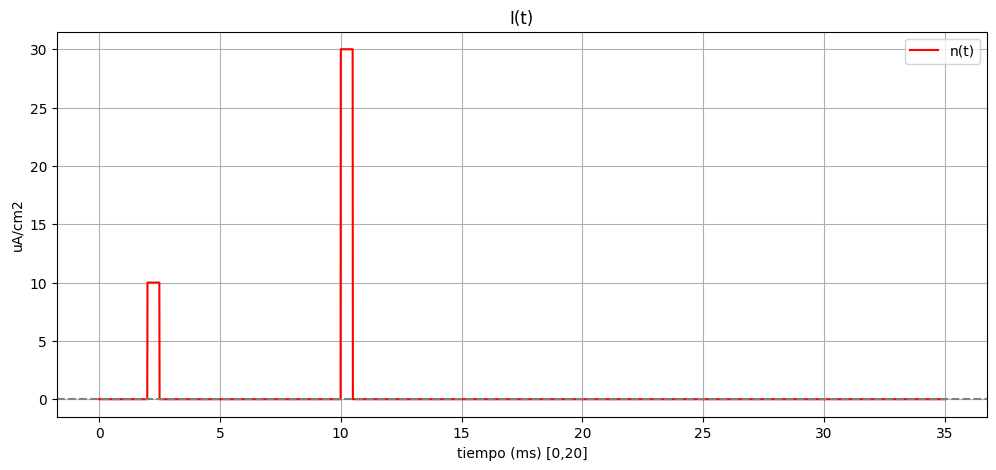

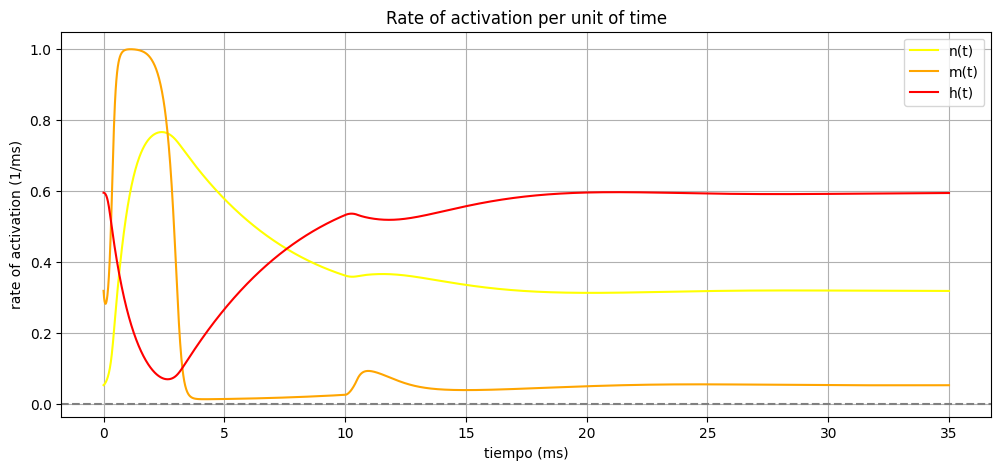

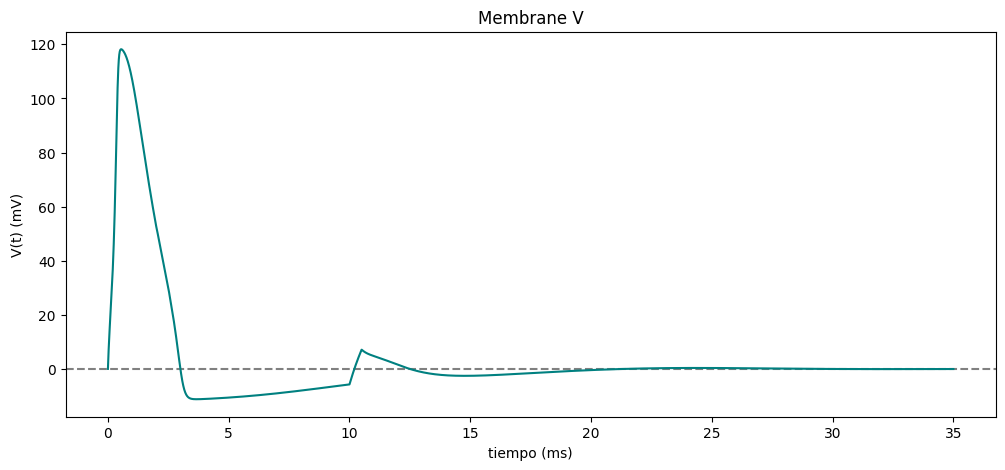

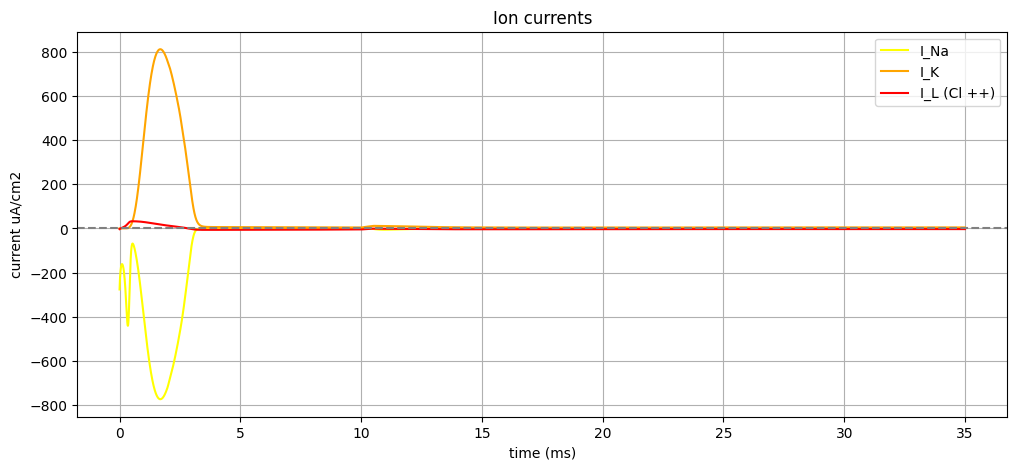

In [38]:
# 4.1)

# ic =cV

def I_4(t):
    if 2.0 <= t <= 2.5:
        return 10
    if 10 <= t <= 10.5:
        return 30
    else:
        return 0


c = 1  # 1uF/cm^2
gNa = 120  # mS/cm^2
gK = 36  # mS/cm^2
gL = 0.3  # mS/cm^2
vNa = 120  # mV
vK = -12  # mV
vL = 10.6  # mV
i0 = 0  # uA/cm^2
t0 = 0  # ms

V0, n0, m0, h0 = v_f, n_f, m_f, h_f
h = 0.01
ti = 0.0

tf = 35.0

k = int((tf - ti) / h)

time = np.linspace(0, tf, k)
plt.figure(figsize=(12, 5))
plt.title("I(t)")
plt.xlabel('tiempo (ms) [0,20]')
plt.ylabel('uA/cm2')
plt.plot(time, [I_4(t) for t in time], label="n(t)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')
plt.legend()
plt.grid()
plt.style.use('default')
plt.show()


def dv_dt(v, m, n, h, t):
    return (1 / c) * (I_4(t) - INa(v, m, h) - IK(v, n) - IL(v))


def dALLdt(X, t, p):
    V, n, m, h = X
    dVdt = dv_dt(V, m, n, h, t)
    dndt = dn_dt(V, n)
    dmdt = dm_dt(V, m)
    dhdt = dh_dt(V, h)
    return np.array([dVdt, dndt, dmdt, dhdt])


t, w = integrador_ode(rk4, dALLdt, np.array([V0, m0, n0, h0]), ti, tf, k, [])

plt.figure(figsize=(12, 5))
plt.title("Rate of activation per unit of time")
plt.xlabel('tiempo (ms)')
plt.ylabel('rate of activation (1/ms)')
plt.plot(t, w[1, :], label="n(t)", linestyle='-', c='yellow')
plt.plot(t, w[2, :], label="m(t)", linestyle='-', c='orange')
plt.plot(t, w[3, :], label="h(t)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')
plt.legend()
plt.grid()
plt.style.use('default')
plt.show()

plt.figure(figsize=(12, 5))
plt.title("Membrane V")
plt.axhline(0, linestyle='--', color='grey')
plt.xlabel('tiempo (ms)')
plt.ylabel('V(t) (mV)')
plt.plot(t, w[0, :], label="v(t)", linestyle='-', c='teal')
plt.show()

INa_values = np.array([
    INa(v, m, h)
    for v, m, h in zip(w[0, :], w[2, :], w[3, :])
])
IK_values = np.array([
    IK(v, n)
    for v, n in zip(w[0, :], w[1, :])
])
IL_values = np.array([
    IL(v)
    for v in w[0, :]
])
plt.figure(figsize=(12, 5))
plt.title("Ion currents")
plt.xlabel('time (ms)')
plt.ylabel('current uA/cm2')
plt.plot(t, INa_values, label="I_Na", linestyle='-', c='yellow')
plt.plot(t, IK_values, label="I_K", linestyle='-', c='orange')
plt.plot(t, IL_values, label="I_L (Cl ++)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')
plt.legend()
plt.grid()
plt.style.use('default')
plt.show()




## Ejercicio 5) ráfaga

**1)** Implemente la corriente de membrana

$$
i(t) = \left\{
\begin{array}{ll}
10 \mu A/cm^2, & t\in [5ms,\infty ms) \\
0 \mu A/cm^2, & c.c. \\
\end{array}
\right.
$$

Esta corriente representa un estímulo constante.

**2)** Integre nuevamente las ODEs para $t\in[0ms,100ms]$, usando como condición incial los valores de equilibrio derivados en el inciso **6)** y un paso de integración $dt=0.01$.

**3)** Grafique nuevamente el potencial de membrana en el rango de tiempos calculado.

**4)** Grafique nuevamente fracciones de compuertas abiertas de cada tipo vs el tiempo.

**5)** Discuta lo que observa y explique.

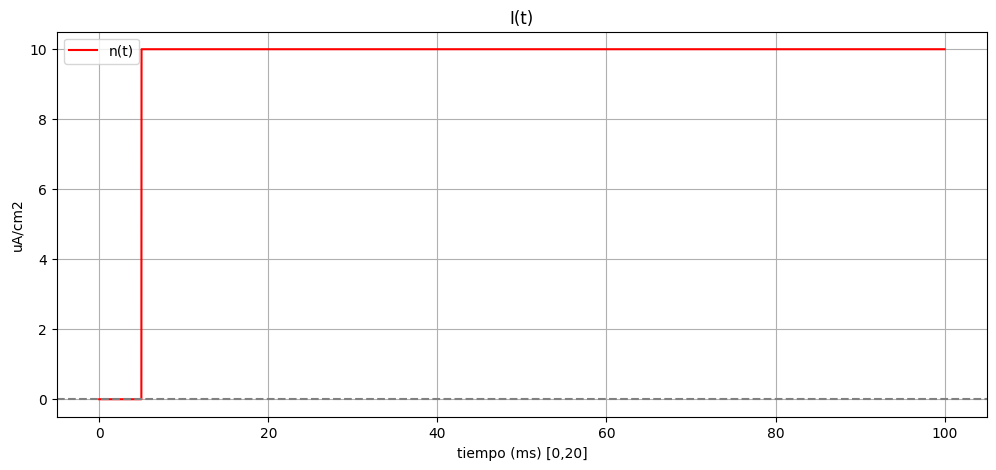

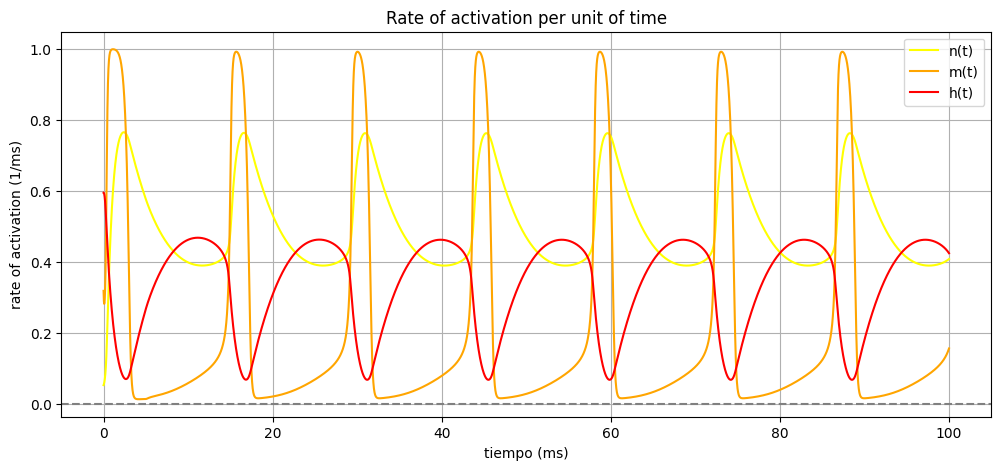

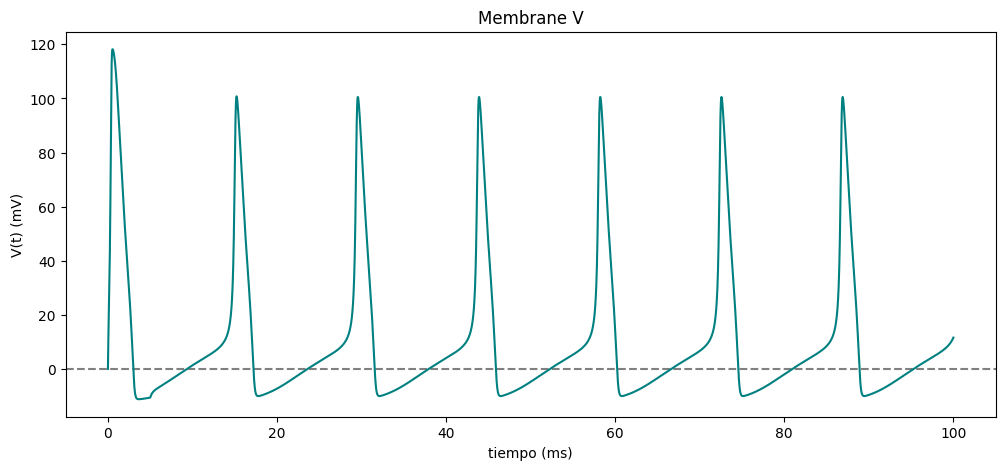

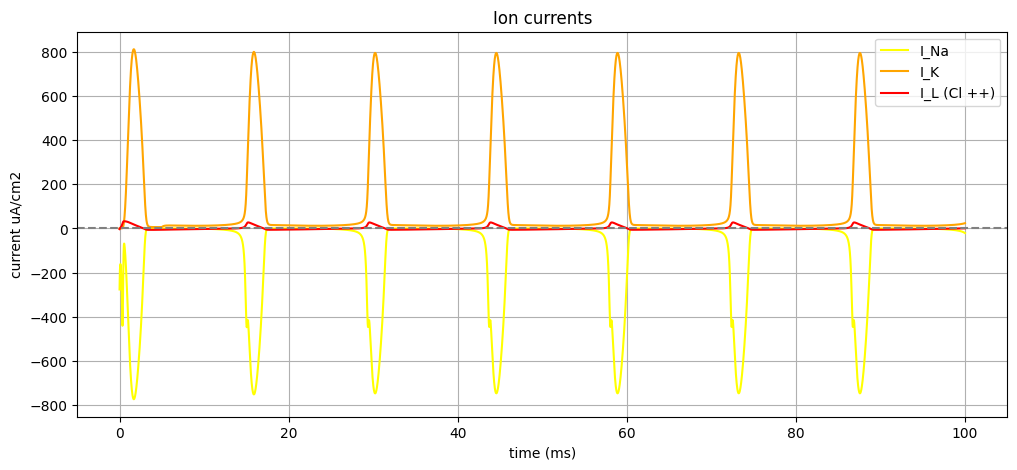

In [41]:
# 5.1)

def I_5(t):
    if 5 <= t:
        return 10
    else:
        return 0


c = 1  # 1uF/cm^2
gNa = 120  # mS/cm^2
gK = 36  # mS/cm^2
gL = 0.3  # mS/cm^2
vNa = 120  # mV
vK = -12  # mV
vL = 10.6  # mV
i0 = 0  # uA/cm^2
t0 = 0  # ms

V0, n0, m0, h0 = v_f, n_f, m_f, h_f
h = 0.01
ti = 0.0

tf = 100.0

k = int((tf - ti) / h)

time = np.linspace(0, tf, k)
plt.figure(figsize=(12, 5))
plt.title("I(t)")
plt.xlabel('tiempo (ms) [0,20]')
plt.ylabel('uA/cm2')
plt.plot(time, [I_5(t) for t in time], label="n(t)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')
plt.legend()
plt.grid()
plt.style.use('default')
plt.show()


def dv_dt(v, m, n, h, t):
    return (1 / c) * (I_5(t) - INa(v, m, h) - IK(v, n) - IL(v))


def dALLdt(X, t, p):
    V, n, m, h = X
    dVdt = dv_dt(V, m, n, h, t)
    dndt = dn_dt(V, n)
    dmdt = dm_dt(V, m)
    dhdt = dh_dt(V, h)
    return np.array([dVdt, dndt, dmdt, dhdt])


t, w = integrador_ode(rk4, dALLdt, np.array([V0, m0, n0, h0]), ti, tf, k, [])

plt.figure(figsize=(12, 5))
plt.title("Rate of activation per unit of time")
plt.xlabel('tiempo (ms)')
plt.ylabel('rate of activation (1/ms)')
plt.plot(t, w[1, :], label="n(t)", linestyle='-', c='yellow')
plt.plot(t, w[2, :], label="m(t)", linestyle='-', c='orange')
plt.plot(t, w[3, :], label="h(t)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')
plt.legend()
plt.grid()
plt.style.use('default')
plt.show()

plt.figure(figsize=(12, 5))
plt.title("Membrane V")
plt.axhline(0, linestyle='--', color='grey')
plt.xlabel('tiempo (ms)')
plt.ylabel('V(t) (mV)')
plt.plot(t, w[0, :], label="v(t)", linestyle='-', c='teal')
plt.show()

INa_values = np.array([
    INa(v, m, h)
    for v, m, h in zip(w[0, :], w[2, :], w[3, :])
])
IK_values = np.array([
    IK(v, n)
    for v, n in zip(w[0, :], w[1, :])
])
IL_values = np.array([
    IL(v)
    for v in w[0, :]
])
plt.figure(figsize=(12, 5))
plt.title("Ion currents")
plt.xlabel('time (ms)')
plt.ylabel('current uA/cm2')
plt.plot(t, INa_values, label="I_Na", linestyle='-', c='yellow')
plt.plot(t, IK_values, label="I_K", linestyle='-', c='orange')
plt.plot(t, IL_values, label="I_L (Cl ++)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')
plt.legend()
plt.grid()
plt.style.use('default')
plt.show()


## Ejercicio 6) período refractario

**1)** Implemente la corriente de membrana

$$
i(t) = \left\{
\begin{array}{ll}
10 \mu A/cm^2, & t\in [10ms\, k,10 ms\, k + 2ms], k \in \{1,2,3,4,5,...\}\\
0 \mu A/cm^2, & c.c. \\
\end{array}
\right.
$$

**2)** Integre nuevamente las ODEs para $t\in[0ms,100ms]$, usando la corriente del inciso **12)**, la condición incial los valores de equilibrio derivados en el inciso **6)** y un paso de integración $dt=0.01$.

**3)** Grafique nuevamente el potencial de membrana en el rango de tiempos calculado.

**4)** Grafique nuevamente fracciones de canales activos e inactivos vs el tiempo.

**5)** Discuta lo que observa y explique.

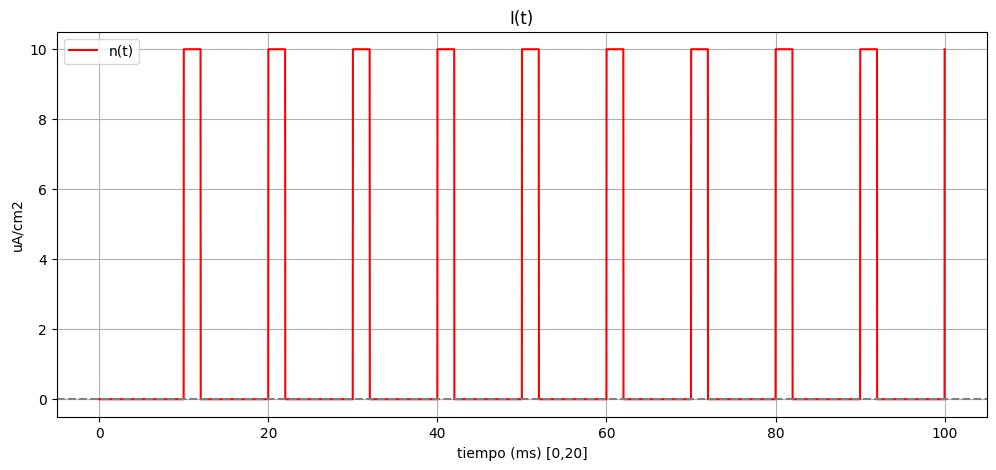

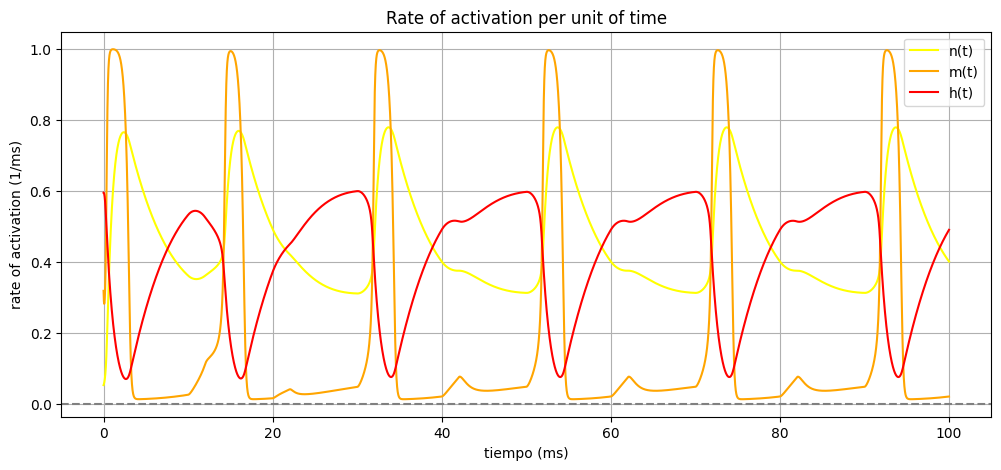

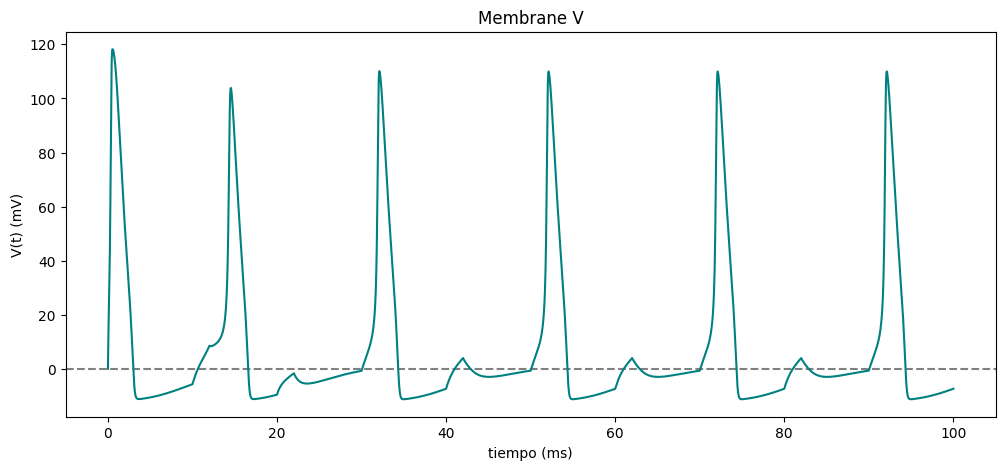

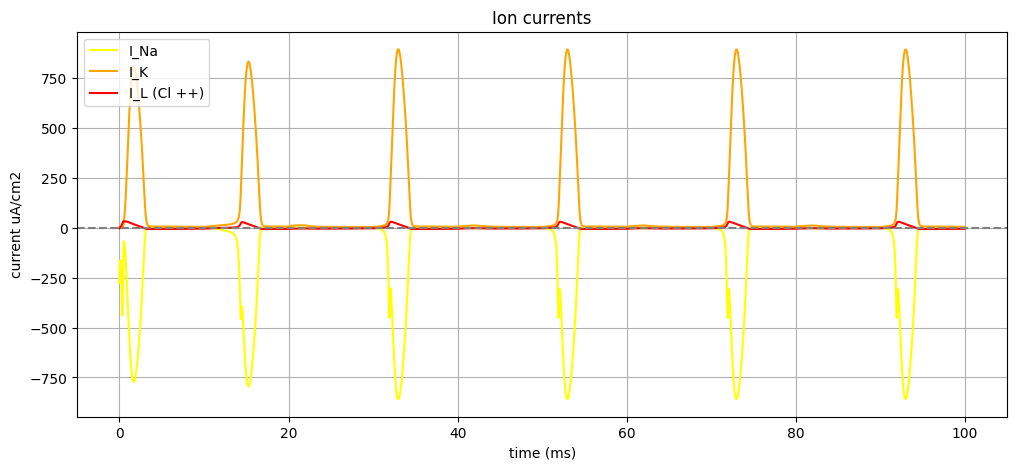

In [42]:
# 6.1)
# 5.1)

def I_6(t):
    k = np.floor(t / 10)
    if k == 0: return 0

    if 10 * k <= t <= 10 * k + 2:
        return 10
    else:
        return 0


c = 1  # 1uF/cm^2
gNa = 120  # mS/cm^2
gK = 36  # mS/cm^2
gL = 0.3  # mS/cm^2
vNa = 120  # mV
vK = -12  # mV
vL = 10.6  # mV
i0 = 0  # uA/cm^2
t0 = 0  # ms

V0, n0, m0, h0 = v_f, n_f, m_f, h_f
h = 0.01
ti = 0.0

tf = 100.0

k = int((tf - ti) / h)

time = np.linspace(0, tf, k)
plt.figure(figsize=(12, 5))
plt.title("I(t)")
plt.xlabel('tiempo (ms) [0,20]')
plt.ylabel('uA/cm2')
plt.plot(time, [I_6(t) for t in time], label="n(t)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')
plt.legend()
plt.grid()
plt.style.use('default')
plt.show()


def dv_dt(v, m, n, h, t):
    return (1 / c) * (I_6(t) - INa(v, m, h) - IK(v, n) - IL(v))


def dALLdt(X, t, p):
    V, n, m, h = X
    dVdt = dv_dt(V, m, n, h, t)
    dndt = dn_dt(V, n)
    dmdt = dm_dt(V, m)
    dhdt = dh_dt(V, h)
    return np.array([dVdt, dndt, dmdt, dhdt])


t, w = integrador_ode(rk4, dALLdt, np.array([V0, m0, n0, h0]), ti, tf, k, [])

plt.figure(figsize=(12, 5))
plt.title("Rate of activation per unit of time")
plt.xlabel('tiempo (ms)')
plt.ylabel('rate of activation (1/ms)')
plt.plot(t, w[1, :], label="n(t)", linestyle='-', c='yellow')
plt.plot(t, w[2, :], label="m(t)", linestyle='-', c='orange')
plt.plot(t, w[3, :], label="h(t)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')
plt.legend()
plt.grid()
plt.style.use('default')
plt.show()

plt.figure(figsize=(12, 5))
plt.title("Membrane V")
plt.axhline(0, linestyle='--', color='grey')
plt.xlabel('tiempo (ms)')
plt.ylabel('V(t) (mV)')
plt.plot(t, w[0, :], label="v(t)", linestyle='-', c='teal')
plt.show()

INa_values = np.array([
    INa(v, m, h)
    for v, m, h in zip(w[0, :], w[2, :], w[3, :])
])
IK_values = np.array([
    IK(v, n)
    for v, n in zip(w[0, :], w[1, :])
])
IL_values = np.array([
    IL(v)
    for v in w[0, :]
])
plt.figure(figsize=(12, 5))
plt.title("Ion currents")
plt.xlabel('time (ms)')
plt.ylabel('current uA/cm2')
plt.plot(t, INa_values, label="I_Na", linestyle='-', c='yellow')
plt.plot(t, IK_values, label="I_K", linestyle='-', c='orange')
plt.plot(t, IL_values, label="I_L (Cl ++)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')
plt.legend()
plt.grid()
plt.style.use('default')
plt.show()




## Ejercicio 7) exitaciones espontáneas en respuesta al ruido

**1)** Implemente una corriente estocástica que retorne un valor $i(t)\sim i_0 N(0,1)$ (i.e. $i_0$ por un valor aleatorio obtenido de una distribución normal de media 0 y varianza 1) para cada valor de $t$ en el que sea evaluada.

**2)** Integre nuevamente las ODEs para $t\in[0ms,500ms]$, usando la corriente del inciso **22)** para $i_0=50\mu A$, la condición incial los valores de equilibrio derivados en el inciso **6)** y un paso de integración $dt=0.01$.
**IMPORTANTE**: para integrar, utilice en este caso el método de Euler, ya que estaríamos integrando un proceso estocástico.

**3)** Grafique nuevamente el potencial de membrana en el rango de tiempos calculado.

**4)** Grafique nuevamente fracciones de compuertas abiertas de cada tipo vs el tiempo.

**5)** Observa picos de activación cada tanto? Aparecen con regularidad? Estime con que frecuencia observa los picos.

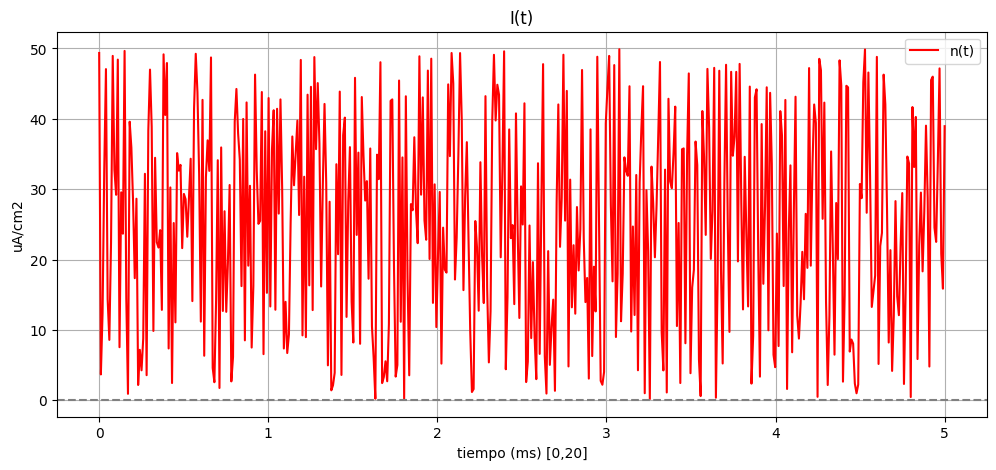

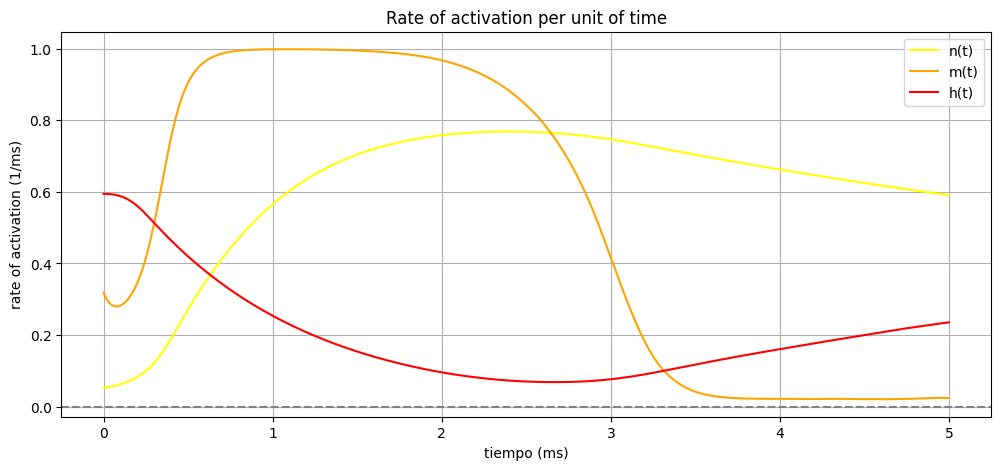

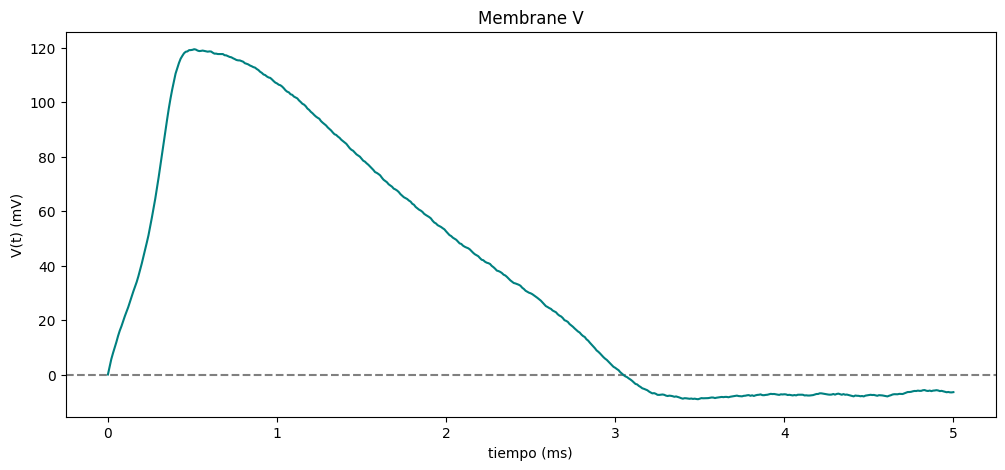

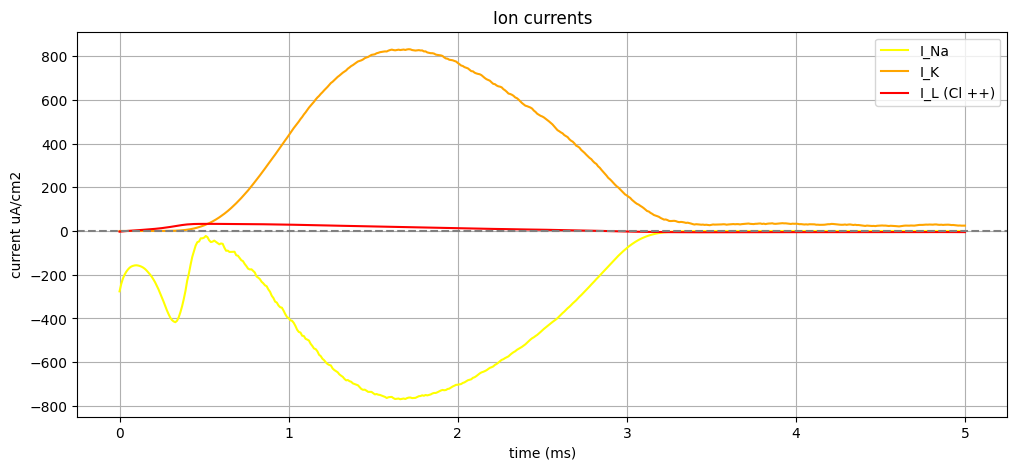

In [45]:
# 7.1)# 6.1)
# 5.1)

def I_7(t):
    rn = np.random.rand()
    return i0 * rn


c = 1  # 1uF/cm^2
gNa = 120  # mS/cm^2
gK = 36  # mS/cm^2
gL = 0.3  # mS/cm^2
vNa = 120  # mV
vK = -12  # mV
vL = 10.6  # mV
i0 = 50  # uA/cm^2
t0 = 0  # ms

V0, n0, m0, h0 = v_f, n_f, m_f, h_f
h = 0.01
ti = 0.0

tf = 50.0

k = int((tf - ti) / h)

time = np.linspace(0, tf, k)
plt.figure(figsize=(12, 5))
plt.title("I(t)")
plt.xlabel('tiempo (ms) [0,20]')
plt.ylabel('uA/cm2')
plt.plot(time, [I_7(t) for t in time], label="n(t)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')
plt.legend()
plt.grid()
plt.style.use('default')
plt.show()


def dv_dt(v, m, n, h, t):
    return (1 / c) * (I_7(t) - INa(v, m, h) - IK(v, n) - IL(v))


def dALLdt(X, t, p):
    V, n, m, h = X
    dVdt = dv_dt(V, m, n, h, t)
    dndt = dn_dt(V, n)
    dmdt = dm_dt(V, m)
    dhdt = dh_dt(V, h)
    return np.array([dVdt, dndt, dmdt, dhdt])


t, w = integrador_ode(euler, dALLdt, np.array([V0, m0, n0, h0]), ti, tf, k, [])

plt.figure(figsize=(12, 5))
plt.title("Rate of activation per unit of time")
plt.xlabel('tiempo (ms)')
plt.ylabel('rate of activation (1/ms)')
plt.plot(t, w[1, :], label="n(t)", linestyle='-', c='yellow')
plt.plot(t, w[2, :], label="m(t)", linestyle='-', c='orange')
plt.plot(t, w[3, :], label="h(t)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')
plt.legend()
plt.grid()
plt.style.use('default')
plt.show()

plt.figure(figsize=(12, 5))
plt.title("Membrane V")
plt.axhline(0, linestyle='--', color='grey')
plt.xlabel('tiempo (ms)')
plt.ylabel('V(t) (mV)')
plt.plot(t, w[0, :], label="v(t)", linestyle='-', c='teal')
plt.show()

INa_values = np.array([
    INa(v, m, h)
    for v, m, h in zip(w[0, :], w[2, :], w[3, :])
])
IK_values = np.array([
    IK(v, n)
    for v, n in zip(w[0, :], w[1, :])
])
IL_values = np.array([
    IL(v)
    for v in w[0, :]
])
plt.figure(figsize=(12, 5))
plt.title("Ion currents")
plt.xlabel('time (ms)')
plt.ylabel('current uA/cm2')
plt.plot(t, INa_values, label="I_Na", linestyle='-', c='yellow')
plt.plot(t, IK_values, label="I_K", linestyle='-', c='orange')
plt.plot(t, IL_values, label="I_L (Cl ++)", linestyle='-', c='red')
plt.axhline(0, linestyle='--', color='grey')
plt.legend()
plt.grid()
plt.style.use('default')
plt.show()


